In [1]:
!pip install numpy pandas scikit-learn matplotlib torch tqdm -q

In [2]:
from __future__ import annotations

import json
import random
import warnings
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import GroupShuffleSplit
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

SEED = 42


def find_dataset_root() -> Path:
    local_candidates = [Path.cwd(), Path.cwd().parent]
    kaggle_input = Path("/kaggle/input")
    candidates = [
        Path("/kaggle/input/datasets/ngcminhnguynl/posture-dataset/Real_Posture_Dataset"),
    ]
    candidates.extend(local_candidates)
    if kaggle_input.exists():
        candidates.extend(path.parent for path in kaggle_input.rglob("labels.csv"))

    for candidate in candidates:
        if (candidate / "labels.csv").is_file() and (candidate / "config" / "labels.json").is_file():
            return candidate
    raise FileNotFoundError("Không tìm thấy dataset: cần labels.csv và config/labels.json")


ROOT = find_dataset_root()
LABELS_CSV = ROOT / "labels.csv"
LABEL_SCHEMA = ROOT / "config" / "labels.json"
REPORT_DIR = Path("/kaggle/working/reports") if Path("/kaggle/working").exists() else ROOT / "reports"
REPORT_DIR.mkdir(exist_ok=True)

def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Root: {ROOT}")
print(f"Device: {DEVICE}")


Root: /kaggle/input/datasets/ngcminhnguynl/posture-dataset/Real_Posture_Dataset
Device: cuda


In [3]:
if not LABELS_CSV.exists():
    raise FileNotFoundError(f"Không tìm thấy {LABELS_CSV}")
manifest = pd.read_csv(LABELS_CSV)
required = {"clip_id", "take_id", "person_id", "session_id", "camera_id", "camera_view", "label", "video_path", "metadata_path", "status"}
missing_columns = required - set(manifest.columns)
if missing_columns:
    raise ValueError(f"labels.csv thiếu cột: {sorted(missing_columns)}")

with LABEL_SCHEMA.open(encoding="utf-8") as file:
    label_schema = json.load(file)
label_names = {int(item["id"]): item["name"] for item in label_schema["labels"]}
num_classes = len(label_names)

def resolve_relative_path(value: str) -> Path:
    return ROOT / Path(str(value).replace("\\", "/"))

manifest["video_file"] = manifest["video_path"].map(resolve_relative_path)
manifest["metadata_file"] = manifest["metadata_path"].map(resolve_relative_path)

KEYPOINT_SUFFIXES = {".txt", ".jsonl", ".json"}
KEYPOINT_HINTS = ("yolo", "keypoint", "pose")

def find_keypoint_file(row: pd.Series) -> Path:
    """Ưu tiên đường dẫn chuẩn; nếu không có thì tìm file keypoint của đúng camera trong thư mục take."""
    camera = row["camera_id"]
    exact = row["metadata_file"].parent / "keypoints" / f"{camera}_yolo17_raw.txt"
    if exact.exists():
        return exact
    for folder in (row["metadata_file"].parent / "keypoints", row["video_file"].parent / "keypoints",
                   row["metadata_file"].parent, row["video_file"].parent):
        if folder.is_dir():
            hits = sorted(p for p in folder.glob(f"{camera}*")
                          if p.suffix.lower() in KEYPOINT_SUFFIXES and any(h in p.name.lower() for h in KEYPOINT_HINTS))
            if hits:
                return hits[0]
    return exact

manifest["keypoint_file"] = manifest.apply(find_keypoint_file, axis=1)
usable_manifest = manifest[manifest["status"].eq("ok")].copy()
usable_manifest["label"] = usable_manifest["label"].astype(int)
bad_labels = sorted(set(usable_manifest["label"]) - set(label_names))
if bad_labels:
    raise ValueError(f"Label ngoài config/labels.json: {bad_labels}")

print(f"Tổng dòng manifest: {len(manifest):,}; dòng ok: {len(usable_manifest):,}; "
      f"số người: {usable_manifest['person_id'].nunique()}")
display(usable_manifest.groupby(["person_id", "camera_id", "label"]).size().unstack(fill_value=0))
display(pd.DataFrame({"label": list(label_names), "name": list(label_names.values())}))

still_missing = usable_manifest[~usable_manifest["keypoint_file"].map(Path.exists)]
print(f"Clip thiếu file keypoint sau khi tìm dự phòng: {len(still_missing)}")
for _, row in still_missing.head(3).iterrows():
    take_dir = row["metadata_file"].parent
    print(f"- {take_dir.relative_to(ROOT)} -> {sorted(p.name for p in take_dir.rglob('*'))[:10]}")

Tổng dòng manifest: 206; dòng ok: 206; số người: 14


label                0  1  2  3  4  5
person_id camera_id                  
CHANH     cam01      2  2  2  2  2  2
          cam02      2  2  2  2  2  2
DGD       cam01      1  1  1  1  1  1
          cam02      1  1  1  1  1  1
DPHI      cam01      1  1  2  2  1  2
          cam02      1  1  2  2  1  2
HDUY      cam01      2  1  1  1  1  1
          cam02      2  1  1  1  1  1
KIET      cam01      1  1  1  1  1  1
          cam02      1  1  1  1  1  1
KNGUYEN   cam01      1  1  1  2  2  2
          cam02      1  1  1  2  2  2
LM        cam01      1  1  1  1  1  1
          cam02      1  1  1  1  1  1
MINHLE    cam01      1  3  1  1  1  1
          cam02      1  3  1  1  1  1
MINHNG    cam01      1  1  1  1  1  1
          cam02      1  1  1  1  1  1
PHU       cam01      1  1  1  1  1  1
          cam02      1  1  1  1  1  1
QBAO      cam01      1  1  1  1  2  1
          cam02      1  1  1  1  2  1
TDUY      cam01      1  4  1  1  1  1
          cam02      1  4  1  1  1  1
TRUONG    cam01      1  1  1  1  1  1
          cam02      1  1  1  1  1  1
VMTRI     cam01      1  1  1  1  1  1
          cam02      1  1  1  1  1  1

,label,name
0,0,Ngồi thẳng
1,1,Cúi gập / gù lưng
2,2,Gục xuống bàn
3,3,Ngả người ra sau
4,4,Nghiêng / quay sang bên
5,5,Giơ tay phát biểu


Clip thiếu file keypoint sau khi tìm dự phòng: 0


In [4]:
missing_video = (~usable_manifest["video_file"].map(Path.exists)).sum()
missing_metadata = (~usable_manifest["metadata_file"].map(Path.exists)).sum()
missing_keypoints = (~usable_manifest["keypoint_file"].map(Path.exists)).sum()
print({"missing_video": int(missing_video), "missing_metadata": int(missing_metadata), "missing_keypoints": int(missing_keypoints)})
display(usable_manifest.groupby("label").size().rename("clips").to_frame().assign(label_name=lambda x: x.index.map(label_names)))

{'missing_video': 0, 'missing_metadata': 0, 'missing_keypoints': 0}


,clips,label_name
label,,
0,32,Ngồi thẳng
1,40,Cúi gập / gù lưng
2,32,Gục xuống bàn
3,34,Ngả người ra sau
4,34,Nghiêng / quay sang bên
5,34,Giơ tay phát biểu


In [5]:
SEQ_LEN = 32
MIN_FRAMES = 4
LR_SWAP = np.array([0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15])

def parse_keypoints(points: Any) -> tuple[np.ndarray, np.ndarray | None] | None:
    try:
        arr = np.asarray(points, dtype=np.float32)
    except (TypeError, ValueError):
        return None
    if arr.ndim == 1 and arr.size in (34, 51):
        arr = arr.reshape(17, -1)
    if arr.ndim != 2 or arr.shape[0] != 17 or arr.shape[1] < 2:
        return None
    return arr[:, :2], (arr[:, 2] if arr.shape[1] >= 3 else None)

def frame_to_raw(record: Any) -> tuple[np.ndarray, np.ndarray, np.ndarray] | None:
    """Trả về (keypoints[17,2], confidence[17], bbox[4]); tự suy bbox từ keypoint nếu thiếu."""
    if not isinstance(record, dict):
        return None
    parsed = parse_keypoints(record.get("keypoints_17") or record.get("keypoints"))
    if parsed is None:
        return None
    kp, kp_conf = parsed
    conf = None
    if record.get("keypoint_confidences") is not None:
        try:
            conf = np.asarray(record["keypoint_confidences"], dtype=np.float32)
        except (TypeError, ValueError):
            conf = None
    if conf is None or conf.shape != (17,):
        conf = kp_conf if kp_conf is not None else np.ones(17, dtype=np.float32)
    if (conf > 0.05).sum() < 3:
        return None
    box = None
    raw_box = record.get("bbox")
    if isinstance(raw_box, list) and len(raw_box) == 4:
        try:
            box = np.asarray(raw_box, dtype=np.float32)
        except (TypeError, ValueError):
            box = None
    if box is None or not np.isfinite(box).all() or box[2] <= box[0] or box[3] <= box[1]:
        pts = kp[conf > 0.2] if (conf > 0.2).sum() >= 3 else kp
        lo, hi = pts.min(axis=0), pts.max(axis=0)
        pad = 0.1 * np.maximum(hi - lo, 1.0)
        box = np.concatenate([lo - pad, hi + pad]).astype(np.float32)
    if not (np.isfinite(kp).all() and np.isfinite(conf).all() and np.isfinite(box).all()):
        return None
    return kp.astype(np.float32), conf.astype(np.float32), box

def load_raw_sequence(path: Path) -> tuple[dict[str, np.ndarray] | None, str, str]:
    """Đọc toàn bộ frame hợp lệ (độ dài thay đổi); việc lấy mẫu 32 frame làm ở Dataset."""
    if not path.exists():
        return None, "missing", str(path)
    kps, cfs, bxs, first_record = [], [], [], None
    with path.open(encoding="utf-8", errors="replace") as file:
        for line in file:
            line = line.strip()
            if not line:
                continue
            try:
                record = json.loads(line)
            except json.JSONDecodeError:
                continue
            first_record = record if first_record is None else first_record
            raw = frame_to_raw(record)
            if raw is not None:
                kps.append(raw[0]); cfs.append(raw[1]); bxs.append(raw[2])
    if len(kps) < MIN_FRAMES:
        return None, "few_frames", f"{path.name}: {len(kps)} frame hợp lệ; record đầu: {repr(first_record)[:250]}"
    return {"kp": np.stack(kps), "cf": np.stack(cfs), "bx": np.stack(bxs)}, "ok", ""

records, skipped = [], {}
for row in tqdm(usable_manifest.to_dict("records"), desc="Đọc keypoints"):
    seq, code, detail = load_raw_sequence(Path(row["keypoint_file"]))
    if seq is None:
        skipped.setdefault(code, []).append((row["clip_id"], detail))
    else:
        records.append({**row, **seq})
if not records:
    raise RuntimeError("Không có sample keypoint hợp lệ để train.")
all_samples = samples = pd.DataFrame(records)
samples["take_key"] = samples["metadata_file"].map(lambda p: str(Path(p).parent))
samples["n_frames"] = samples["kp"].map(len)

print(f"Samples hợp lệ: {len(samples)}/{len(usable_manifest)}; bỏ qua: { {k: len(v) for k, v in skipped.items()} }")
for code, items in skipped.items():
    for clip_id, detail in items[:2]:
        print(f"  [{code}] {clip_id}: {detail}")
display(samples["n_frames"].describe().to_frame().T)
display(samples.groupby(["person_id", "camera_id"]).size().unstack(fill_value=0))

Đọc keypoints:   0%|          | 0/206 [00:00<?, ?it/s]

Samples hợp lệ: 205/206; bỏ qua: {'few_frames': 1}
  [few_frames] VMTRI_session_20261027_1124_L5_take_001_cam01: cam01_yolo17_raw.txt: 3 frame hợp lệ; record đầu: {'frame_index': 0, 'relative_ms': 0, 'host_utc': '2026-10-27T04:46:53.852649Z', 'width': 1280, 'height': 720, 'backend': 'yolo', 'person_count': 2, 'status': 'ok', 'keypoints': [[602.4263305664062, 333.7035827636719, 0.9880368709564209], [614.6938476


,count,mean,std,min,25%,50%,75%,max
n_frames,205.0,107.239024,75.000042,4.0,70.0,76.0,117.0,498.0


camera_id,cam01,cam02
person_id,,
CHANH,12,12
DGD,6,6
DPHI,9,9
HDUY,7,7
KIET,6,6
KNGUYEN,9,9
LM,6,6
MINHLE,8,8
MINHNG,6,6


In [6]:
EPS = 1e-6
N_GEO = 10

def frame_features(kp: np.ndarray, cf: np.ndarray, bx: np.ndarray, mode: str) -> np.ndarray:
    """kp[T,17,2], cf[T,17], bx[T,4] -> đặc trưng theo frame.
    legacy: toạ độ chuẩn hóa theo bbox + confidence (như bản gốc).
    new: toạ độ tương đối so với trung điểm vai (chia theo bề rộng vai) + confidence + 10 đặc trưng hình học."""
    T = len(kp)
    w, h = np.maximum(bx[:, 2] - bx[:, 0], 1.0), np.maximum(bx[:, 3] - bx[:, 1], 1.0)
    if mode == "legacy":
        xy = (kp - bx[:, None, :2]) / np.stack([w, h], axis=1)[:, None, :]
        return np.concatenate([xy.reshape(T, -1), cf], axis=1)
    shoulder_mid = kp[:, 5:7].mean(axis=1)
    hip_mid = kp[:, 11:13].mean(axis=1)
    shoulder_w = np.linalg.norm(kp[:, 5] - kp[:, 6], axis=1)
    scale = np.maximum(shoulder_w, 0.25 * h)
    rel = np.clip((kp - shoulder_mid[:, None, :]) / scale[:, None, None], -6.0, 6.0)
    nose = rel[:, 0]
    nose_dist = np.linalg.norm(nose, axis=1)
    shoulder_vec = kp[:, 6] - kp[:, 5]
    hips_visible = np.minimum(cf[:, 11], cf[:, 12]) > 0.3
    wrist_up = np.where(cf[:, 9:11] > 0.2, -rel[:, 9:11, 1], -1.0).max(axis=1)
    geo = np.stack([
        nose[:, 0] / (nose_dist + EPS),
        -nose[:, 1] / (nose_dist + EPS),
        nose_dist,
        np.clip(shoulder_vec[:, 1] / (shoulder_w + EPS), -1.0, 1.0),
        shoulder_w / h,
        np.where(hips_visible, np.linalg.norm(shoulder_mid - hip_mid, axis=1) / h, 0.0),
        rel[:, 3:5, 1].mean(axis=1),
        wrist_up,
        np.log(w / h),
        0.5 * np.log(w * h),
    ], axis=1)
    return np.concatenate([rel.reshape(T, -1), cf, geo], axis=1)

def sequence_features(kp: np.ndarray, cf: np.ndarray, bx: np.ndarray, mode: str) -> np.ndarray:
    feats = frame_features(kp, cf, bx, mode)
    if mode == "new":
        feats[:, -1] -= feats[:, -1].mean()
        geo = feats[:, -N_GEO:]
        feats = np.concatenate([feats, np.diff(geo, axis=0, prepend=geo[:1])], axis=1)
    return np.nan_to_num(feats, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

def sample_indices(n: int, train: bool, rng: np.random.Generator) -> np.ndarray:
    """Eval: lấy đều SEQ_LEN frame. Train: cắt ngẫu nhiên hai đầu + jitter thời gian."""
    if not train or n < 2:
        return np.linspace(0, n - 1, SEQ_LEN).round().astype(int)
    lo = rng.uniform(0.0, 0.15) * (n - 1)
    hi = (n - 1) * (1.0 - rng.uniform(0.0, 0.15))
    idx = np.linspace(lo, hi, SEQ_LEN) + rng.normal(0.0, 0.01 * (n - 1), SEQ_LEN)
    return np.sort(np.clip(idx.round().astype(int), 0, n - 1))

def augment_clip(kp: np.ndarray, cf: np.ndarray, bx: np.ndarray, rng: np.random.Generator):
    """Lật ngang, scale, xoay nhẹ, nhiễu toạ độ/confidence; cùng một phép biến đổi cho cả clip."""
    kp, cf = kp.copy(), cf.copy()
    center = (bx[:, :2] + bx[:, 2:]) / 2
    size = np.maximum(bx[:, 2:] - bx[:, :2], 1.0)
    if rng.random() < 0.5:
        kp[:, :, 0] = 2 * center[:, None, 0] - kp[:, :, 0]
        kp, cf = kp[:, LR_SWAP], cf[:, LR_SWAP]
    scale = rng.uniform(0.9, 1.1)
    theta = np.deg2rad(rng.uniform(-5.0, 5.0))
    rot = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]], dtype=np.float32)
    kp = ((kp - center[:, None, :]) * scale) @ rot.T + center[:, None, :]
    half = size * scale / 2
    bx = np.concatenate([center - half, center + half], axis=1)
    kp = kp + rng.normal(0.0, 0.01, kp.shape).astype(np.float32) * size[:, None, :]
    cf = np.clip(cf + rng.normal(0.0, 0.03, cf.shape).astype(np.float32), 0.0, 1.0)
    return kp.astype(np.float32), cf.astype(np.float32), bx.astype(np.float32)

def mirror_clip(kp: np.ndarray, cf: np.ndarray, bx: np.ndarray):
    """Lật ngang xác định (dùng cho test-time augmentation)."""
    kp = kp.copy()
    kp[:, :, 0] = (bx[:, 0] + bx[:, 2])[:, None] - kp[:, :, 0]
    return kp, cf[:, LR_SWAP], bx

def fit_standardizer(frame: pd.DataFrame, mode: str) -> dict[str, np.ndarray]:
    rng = np.random.default_rng(0)
    feats = np.concatenate([
        sequence_features(k[i], c[i], b[i], mode)
        for k, c, b in zip(frame["kp"], frame["cf"], frame["bx"])
        for i in [sample_indices(len(k), False, rng)]
    ])
    return {"mean": feats.mean(axis=0), "std": feats.std(axis=0) + 1e-3}

def make_person_folds(frame: pd.DataFrame, n_folds: int, seed: int) -> list[list[str]]:
    """Chia theo người: mọi clip của một người (cả 2 camera) nằm trong cùng một fold."""
    people = np.array(sorted(frame["person_id"].unique()))
    order = np.random.default_rng(seed).permutation(len(people))
    return [list(group) for group in np.array_split(people[order], n_folds)]

def compute_metrics(targets: np.ndarray, predictions: np.ndarray) -> dict[str, float]:
    return {
        "accuracy": accuracy_score(targets, predictions),
        "balanced_accuracy": balanced_accuracy_score(targets, predictions),
        "macro_f1": f1_score(targets, predictions, average="macro", zero_division=0),
    }

def fuse_by_take(proba: np.ndarray, keys: np.ndarray, how: str = "mean") -> np.ndarray:
    """Gộp dự đoán các camera của cùng một take. how='logmean' = trung bình hình học."""
    values = np.log(proba + 1e-8) if how == "logmean" else proba
    return pd.DataFrame(values).groupby(keys).transform("mean").to_numpy()

N_TEST_PEOPLE = 3
TEST_PEOPLE: list[str] | None = None

def choose_test_people(frame: pd.DataFrame, n_test: int, seed: int, min_clips_per_class: int = 3) -> list[str]:
    """Chọn ngẫu nhiên (có seed) n_test người sao cho tập test có đủ mọi nhãn."""
    people = np.array(sorted(frame["person_id"].unique()))
    rng = np.random.default_rng(seed)
    best, best_score = None, -1
    for _ in range(2000):
        pick = list(rng.choice(people, size=n_test, replace=False))
        counts = np.bincount(frame.loc[frame["person_id"].isin(pick), "label"], minlength=num_classes)
        if counts.min() >= min_clips_per_class:
            return sorted(str(p) for p in pick)
        if counts.min() > best_score:
            best, best_score = pick, counts.min()
    warnings.warn(f"Không tìm được tập test đủ {min_clips_per_class} clip/nhãn; dùng phương án tốt nhất.")
    return sorted(str(p) for p in best)

test_people = sorted(TEST_PEOPLE) if TEST_PEOPLE else choose_test_people(all_samples, N_TEST_PEOPLE, SEED)
is_test = all_samples["person_id"].isin(test_people)
test_df = all_samples[is_test].reset_index(drop=True)
samples = all_samples[~is_test].reset_index(drop=True)
assert set(test_df["person_id"]).isdisjoint(samples["person_id"]), "Rò rỉ người giữa dev và test"
assert set(test_df["take_key"]).isdisjoint(samples["take_key"]), "Rò rỉ take giữa dev và test"
print(f"TEST ({len(test_df)} clip): {test_people}")
print(f"DEV  ({len(samples)} clip): {sorted(samples['person_id'].unique())}")
display(pd.concat({"dev": samples, "test": test_df}).groupby(level=0)["label"].value_counts().unstack(fill_value=0))
all_samples.assign(split=np.where(is_test, "test", "dev"))[["clip_id", "person_id", "camera_id", "label", "split"]] \
    .to_csv(REPORT_DIR / "split_manifest.csv", index=False)

take_keys = samples["take_key"].to_numpy()
targets_all = samples["label"].to_numpy()
label_ids = list(range(num_classes))
target_names = [label_names[i] for i in label_ids]
print({mode: sequence_features(samples.iloc[0]["kp"][:SEQ_LEN], samples.iloc[0]["cf"][:SEQ_LEN],
                               samples.iloc[0]["bx"][:SEQ_LEN], mode).shape for mode in ("legacy", "new")})

TEST (38 clip): ['DGD', 'PHU', 'QBAO']
DEV  (167 clip): ['CHANH', 'DPHI', 'HDUY', 'KIET', 'KNGUYEN', 'LM', 'MINHLE', 'MINHNG', 'TDUY', 'TRUONG', 'VMTRI']


label,0,1,2,3,4,5
dev,26,34,26,28,26,27
test,6,6,6,6,8,6


{'legacy': (32, 51), 'new': (32, 71)}


In [7]:
class PoseSequenceDataset(Dataset):
    """Tính đặc trưng từ keypoint thô; ở chế độ augment, mỗi lần lấy mẫu là một biến thể mới."""
    def __init__(self, frame: pd.DataFrame, mode: str, stats: dict[str, np.ndarray],
                 augment: bool = False, seed: int = 0, mirror: bool = False) -> None:
        self.kp, self.cf, self.bx = list(frame["kp"]), list(frame["cf"]), list(frame["bx"])
        self.y = torch.tensor(frame["label"].to_numpy(), dtype=torch.long)
        self.mode, self.stats, self.augment, self.mirror = mode, stats, augment, mirror
        self.rng = np.random.default_rng(seed)
        self.cache = None if augment else [self._build(i) for i in range(len(self.y))]

    def _build(self, i: int) -> torch.Tensor:
        idx = sample_indices(len(self.kp[i]), self.augment, self.rng)
        kp, cf, bx = self.kp[i][idx], self.cf[i][idx], self.bx[i][idx]
        if self.mirror:
            kp, cf, bx = mirror_clip(kp, cf, bx)
        if self.augment:
            kp, cf, bx = augment_clip(kp, cf, bx, self.rng)
        feats = sequence_features(kp, cf, bx, self.mode)
        feats = np.clip((feats - self.stats["mean"]) / self.stats["std"], -8.0, 8.0)
        return torch.from_numpy(feats.astype(np.float32))

    def __len__(self) -> int:
        return len(self.y)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        x = self.cache[index] if self.cache is not None else self._build(index)
        return x, self.y[index]

class PoseGRUClassifier(nn.Module):
    """GRU hai chiều 1 lớp + mean/max pooling theo thời gian (nhỏ hơn bản gốc để giảm overfit)."""
    def __init__(self, input_dim: int, hidden_dim: int, classes: int, dropout: float = 0.4) -> None:
        super().__init__()
        self.input_drop = nn.Dropout(0.1)
        self.gru = nn.GRU(input_dim, hidden_dim, num_layers=1, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.LayerNorm(hidden_dim * 4), nn.Dropout(dropout), nn.Linear(hidden_dim * 4, classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out, _ = self.gru(self.input_drop(x))
        return self.head(torch.cat([out.mean(dim=1), out.amax(dim=1)], dim=1))

@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, criterion: nn.Module | None = None) -> tuple[float, np.ndarray]:
    model.eval()
    total, count, probs = 0.0, 0, []
    for features, labels in loader:
        logits = model(features.to(DEVICE))
        if criterion is not None:
            total += criterion(logits, labels.to(DEVICE)).item() * len(labels)
        count += len(labels)
        probs.append(torch.softmax(logits, dim=1).cpu().numpy())
    return total / max(count, 1), np.concatenate(probs)

def predict_frame(model: nn.Module, frame: pd.DataFrame, mode: str, stats: dict[str, np.ndarray], tta: bool) -> np.ndarray:
    """Xác suất cho từng clip; tta=True: trung bình bản gốc và bản lật ngang."""
    probs = []
    for mirror in ([False, True] if tta else [False]):
        loader = DataLoader(PoseSequenceDataset(frame, mode, stats, mirror=mirror), batch_size=64, shuffle=False)
        probs.append(predict(model, loader)[1])
    return np.mean(probs, axis=0)

HIDDEN = 32
MAX_EPOCHS, PATIENCE = 120, 20

def train_one(train_df: pd.DataFrame, val_df: pd.DataFrame | None, mode: str, augment: bool, seed: int,
              hidden: int = HIDDEN, dropout: float = 0.4, fixed_epochs: int | None = None):
    """Có val_df: early stopping theo val loss. fixed_epochs: train số epoch cố định, không cần val (train cuối)."""
    seed_everything(seed)
    stats = fit_standardizer(train_df, mode)
    train_ds = PoseSequenceDataset(train_df, mode, stats, augment=augment, seed=seed)
    train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(seed))
    use_val = fixed_epochs is None
    val_loader = DataLoader(PoseSequenceDataset(val_df, mode, stats), batch_size=64, shuffle=False) if use_val else None

    model = PoseGRUClassifier(len(stats["mean"]), hidden, num_classes, dropout).to(DEVICE)
    counts = np.bincount(train_df["label"].to_numpy(), minlength=num_classes)
    weights = len(train_df) / (num_classes * np.maximum(counts, 1))
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=DEVICE), label_smoothing=0.1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

    best_loss, best_state, best_epoch, stale, history = np.inf, None, 0, 0, []
    for epoch in range(1, (MAX_EPOCHS if use_val else fixed_epochs) + 1):
        model.train()
        total = 0.0
        for features, labels in train_loader:
            features, labels = features.to(DEVICE), labels.to(DEVICE)
            loss = criterion(model(features), labels)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total += loss.item() * len(labels)
        row = {"epoch": epoch, "train_loss": total / len(train_ds)}
        if use_val:
            row["val_loss"], _ = predict(model, val_loader, criterion)
            if row["val_loss"] < best_loss - 1e-3:
                best_loss, best_epoch, stale = row["val_loss"], epoch, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                stale += 1
        history.append(row)
        if use_val and stale >= PATIENCE:
            break
    if use_val:
        model.load_state_dict(best_state)
    return model, stats, history, (best_epoch if use_val else fixed_epochs)

In [8]:
N_FOLDS, N_REPEATS, N_VAL_PEOPLE, N_FINAL_SEEDS = 5, 2, 2, 10
EXPERIMENTS = {
    "legacy_features":      {"mode": "legacy", "augment": False, "hidden": 32},
    "new_features":         {"mode": "new",    "augment": False, "hidden": 32},
    "new_features_aug":     {"mode": "new",    "augment": True,  "hidden": 32},
    "new_features_aug_h16": {"mode": "new",    "augment": True,  "hidden": 16},
    "new_features_aug_h64": {"mode": "new",    "augment": True,  "hidden": 64},
}
split_rows: list[dict[str, Any]] = []

def run_experiment(name: str, mode: str, augment: bool, hidden: int) -> dict[str, Any]:
    """Cross-validation theo người CHỈ trên tập DEV. Mỗi clip dev được dự đoán bởi model chưa thấy người đó."""
    oof = np.zeros((N_REPEATS, len(samples), num_classes), dtype=np.float32)
    best_epochs, histories = [], []
    with tqdm(total=N_REPEATS * N_FOLDS, desc=name) as progress:
        for rep in range(N_REPEATS):
            for fold_id, held_out in enumerate(make_person_folds(samples, N_FOLDS, SEED + rep)):
                seed = SEED + 100 * rep + fold_id
                held_mask = samples["person_id"].isin(held_out).to_numpy()
                rest = samples[~held_mask]
                rest_people = np.array(sorted(rest["person_id"].unique()))
                val_people = np.random.default_rng(seed).choice(
                    rest_people, size=min(N_VAL_PEOPLE, len(rest_people) - 1), replace=False)
                is_val = rest["person_id"].isin(val_people)
                train_df, val_df, held = rest[~is_val], rest[is_val], samples[held_mask]

                groups = {"train": train_df, "validation": val_df, "test": held}
                for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
                    assert set(groups[a]["person_id"]).isdisjoint(groups[b]["person_id"]), f"Rò rỉ người: {a}/{b}"
                    assert set(groups[a]["take_key"]).isdisjoint(groups[b]["take_key"]), f"Rò rỉ take: {a}/{b}"
                split_rows.append({"experiment": name, "repeat": rep, "fold": fold_id,
                                   **{f"{k}_people": ",".join(sorted(g["person_id"].unique())) for k, g in groups.items()},
                                   **{f"{k}_clips": len(g) for k, g in groups.items()}})

                model, stats, history, best_epoch = train_one(train_df, val_df, mode, augment, seed, hidden=hidden)
                oof[rep, np.flatnonzero(held_mask)] = predict_frame(model, held, mode, stats, tta=augment)
                best_epochs.append(best_epoch)
                histories += [{**row, "repeat": rep, "fold": fold_id} for row in history]
                progress.update(1)
    return {"oof": oof, "best_epochs": best_epochs, "history": pd.DataFrame(histories)}

def summarize(name: str, oof: np.ndarray) -> dict[str, Any]:
    single = [compute_metrics(targets_all, oof[r].argmax(1)) for r in range(len(oof))]
    fused = [compute_metrics(targets_all, fuse_by_take(oof[r], take_keys).argmax(1)) for r in range(len(oof))]
    ens = compute_metrics(targets_all, fuse_by_take(oof.mean(axis=0), take_keys).argmax(1))
    ms = lambda rows, key: (np.mean([r[key] for r in rows]), np.std([r[key] for r in rows]))
    return {
        "experiment": name,
        "single_macro_f1": f"{ms(single, 'macro_f1')[0]:.3f} ± {ms(single, 'macro_f1')[1]:.3f}",
        "fused_macro_f1": f"{ms(fused, 'macro_f1')[0]:.3f} ± {ms(fused, 'macro_f1')[1]:.3f}",
        "fused_accuracy": f"{ms(fused, 'accuracy')[0]:.3f} ± {ms(fused, 'accuracy')[1]:.3f}",
        "ensemble_fused_macro_f1": round(ens["macro_f1"], 3),
        "_fused_f1_mean": ms(fused, "macro_f1")[0], "_single_f1_mean": ms(single, "macro_f1")[0],
        "_fused_f1_std": ms(fused, "macro_f1")[1], "_single_f1_std": ms(single, "macro_f1")[1],
    }

print(f"DEV: {samples['person_id'].nunique()} người, {N_FOLDS}-fold theo người x {N_REPEATS} lần lặp")
results = {name: run_experiment(name, **cfg) for name, cfg in EXPERIMENTS.items()}
summary_df = pd.DataFrame([summarize(name, res["oof"]) for name, res in results.items()])
display(summary_df.drop(columns=[c for c in summary_df if c.startswith("_")]))
split_manifest_cv = pd.DataFrame(split_rows)
split_manifest_cv.to_csv(REPORT_DIR / "cv_split_manifest.csv", index=False)

FINAL_EXPERIMENT = summary_df.loc[summary_df["_fused_f1_mean"].idxmax(), "experiment"]
final_cfg = EXPERIMENTS[FINAL_EXPERIMENT]
final_epochs = int(np.clip(np.median(results[FINAL_EXPERIMENT]["best_epochs"]), 20, MAX_EPOCHS))
print(f"Cấu hình được chọn (theo CV trên DEV): {FINAL_EXPERIMENT} {final_cfg}; số epoch train cuối = {final_epochs}")

final_models = []
for member in tqdm(range(N_FINAL_SEEDS), desc="Train ensemble cuối"):
    model, stats, _, _ = train_one(samples, None, final_cfg["mode"], final_cfg["augment"], SEED + 1000 + member,
                                   hidden=final_cfg["hidden"], fixed_epochs=final_epochs)
    final_models.append({"model": model, "stats": stats})
torch.save({"experiment": FINAL_EXPERIMENT, "config": final_cfg, "epochs": final_epochs,
            "label_names": label_names, "seq_len": SEQ_LEN,
            "members": [{"state": {k: v.cpu().clone() for k, v in m["model"].state_dict().items()},
                         "mean": m["stats"]["mean"].tolist(), "std": m["stats"]["std"].tolist()} for m in final_models]},
           REPORT_DIR / "posture_gru_ensemble.pt")
print(f"Đã lưu ensemble {len(final_models)} model -> {REPORT_DIR / 'posture_gru_ensemble.pt'}")

DEV: 11 người, 5-fold theo người x 2 lần lặp


legacy_features:   0%|          | 0/10 [00:00<?, ?it/s]

new_features:   0%|          | 0/10 [00:00<?, ?it/s]

new_features_aug:   0%|          | 0/10 [00:00<?, ?it/s]

new_features_aug_h16:   0%|          | 0/10 [00:00<?, ?it/s]

new_features_aug_h64:   0%|          | 0/10 [00:00<?, ?it/s]

,experiment,single_macro_f1,fused_macro_f1,fused_accuracy,ensemble_fused_macro_f1
0,legacy_features,0.869 ± 0.007,0.887 ± 0.006,0.886 ± 0.006,0.892
1,new_features,0.884 ± 0.000,0.917 ± 0.011,0.916 ± 0.012,0.905
2,new_features_aug,0.858 ± 0.003,0.875 ± 0.019,0.874 ± 0.018,0.894
3,new_features_aug_h16,0.842 ± 0.002,0.869 ± 0.001,0.868 ± 0.000,0.870
4,new_features_aug_h64,0.867 ± 0.019,0.892 ± 0.001,0.892 ± 0.000,0.892


Cấu hình được chọn (theo CV trên DEV): new_features {'mode': 'new', 'augment': False, 'hidden': 32}; số epoch train cuối = 45


Train ensemble cuối:   0%|          | 0/10 [00:00<?, ?it/s]

Đã lưu ensemble 10 model -> /kaggle/working/reports/posture_gru_ensemble.pt


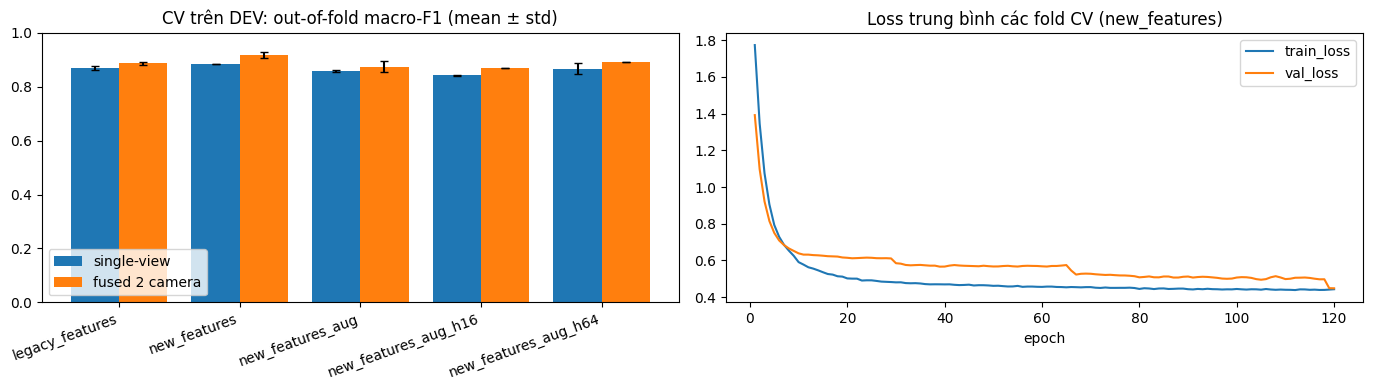

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(summary_df))
axes[0].bar(x - 0.2, summary_df["_single_f1_mean"], 0.4, yerr=summary_df["_single_f1_std"], label="single-view", capsize=3)
axes[0].bar(x + 0.2, summary_df["_fused_f1_mean"], 0.4, yerr=summary_df["_fused_f1_std"], label="fused 2 camera", capsize=3)
axes[0].set_xticks(x)
axes[0].set_xticklabels(summary_df["experiment"], rotation=20, ha="right")
axes[0].set_ylim(0, 1)
axes[0].set_title("CV trên DEV: out-of-fold macro-F1 (mean ± std)")
axes[0].legend()

curves = results[FINAL_EXPERIMENT]["history"].groupby("epoch")[["train_loss", "val_loss"]].mean()
curves.plot(ax=axes[1], title=f"Loss trung bình các fold CV ({FINAL_EXPERIMENT})")
axes[1].set_xlabel("epoch")
plt.tight_layout()
plt.show()

{
  "experiment": "new_features",
  "config": {
    "mode": "new",
    "augment": false,
    "hidden": 32
  },
  "single_view": {
    "accuracy": 1.0,
    "balanced_accuracy": 1.0,
    "macro_f1": 1.0
  },
  "fused_mean_prob": {
    "accuracy": 1.0,
    "balanced_accuracy": 1.0,
    "macro_f1": 1.0
  },
  "fused_log_prob": {
    "accuracy": 1.0,
    "balanced_accuracy": 1.0,
    "macro_f1": 1.0
  },
  "fused_accuracy_95ci_bootstrap_by_take": [
    1.0,
    1.0
  ],
  "single_member_fused_macro_f1": {
    "mean": 1.0,
    "std": 0.0
  },
  "n_test_samples": 38,
  "n_test_takes": 19,
  "test_people": [
    "DGD",
    "PHU",
    "QBAO"
  ],
  "cv_dev": {
    "experiment": "new_features",
    "single_macro_f1": "0.884 ± 0.000",
    "fused_macro_f1": "0.917 ± 0.011",
    "fused_accuracy": "0.916 ± 0.012",
    "ensemble_fused_macro_f1": 0.905
  },
  "protocol": "test cố định 3 người; chọn cấu hình bằng 5-fold theo người x 2 trên dev; ensemble 10 seed train trên toàn bộ dev"
}


,precision,recall,f1-score,support
Ngồi thẳng,1.0,1.0,1.0,6.0
Cúi gập / gù lưng,1.0,1.0,1.0,6.0
Gục xuống bàn,1.0,1.0,1.0,6.0
Ngả người ra sau,1.0,1.0,1.0,6.0
Nghiêng / quay sang bên,1.0,1.0,1.0,8.0
Giơ tay phát biểu,1.0,1.0,1.0,6.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,38.0
weighted avg,1.0,1.0,1.0,38.0


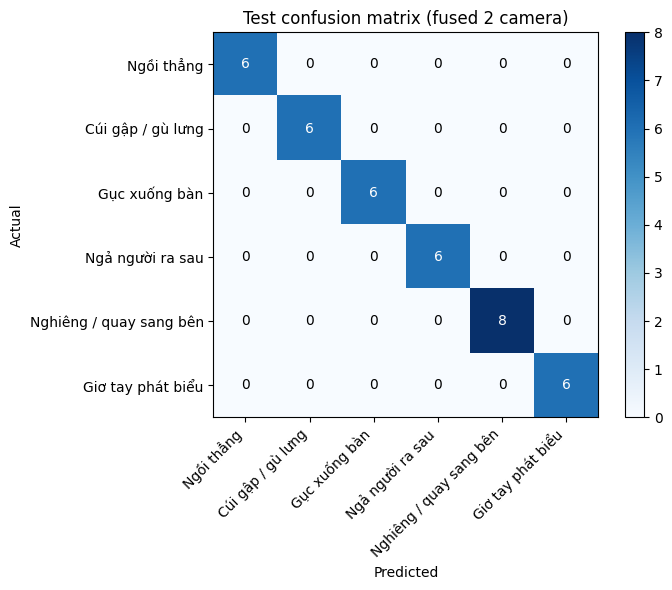

,person_id,n,accuracy,balanced_accuracy,macro_f1
0,DGD,12,1.0,1.0,1.0
1,PHU,12,1.0,1.0,1.0
2,QBAO,14,1.0,1.0,1.0


,camera_id,n,accuracy,balanced_accuracy,macro_f1
0,cam01,19,1.0,1.0,1.0
1,cam02,19,1.0,1.0,1.0


In [10]:
test_targets = test_df["label"].to_numpy()
test_take_keys = test_df["take_key"].to_numpy()
member_proba = np.stack([predict_frame(m["model"], test_df, final_cfg["mode"], m["stats"], tta=final_cfg["augment"])
                         for m in final_models])
test_proba = member_proba.mean(axis=0)
single_predictions = test_proba.argmax(axis=1)
fused_predictions = fuse_by_take(test_proba, test_take_keys).argmax(axis=1)
logfused_predictions = fuse_by_take(test_proba, test_take_keys, "logmean").argmax(axis=1)

def bootstrap_accuracy_ci(pred: np.ndarray, targets: np.ndarray, keys: np.ndarray, n: int = 2000) -> list[float]:
    """Khoảng tin cậy 95% bootstrap theo take (chỉ tham khảo: test chỉ có vài người)."""
    rng = np.random.default_rng(SEED)
    takes = np.unique(keys)
    rows = {k: np.flatnonzero(keys == k) for k in takes}
    accs = [(lambda idx: (pred[idx] == targets[idx]).mean())(np.concatenate([rows[k] for k in rng.choice(takes, len(takes))]))
            for _ in range(n)]
    return [round(float(v), 3) for v in np.percentile(accs, [2.5, 97.5])]

member_fused_f1 = [f1_score(test_targets, fuse_by_take(p, test_take_keys).argmax(1), average="macro", zero_division=0)
                   for p in member_proba]
metrics = {
    "experiment": FINAL_EXPERIMENT,
    "config": final_cfg,
    "single_view": compute_metrics(test_targets, single_predictions),
    "fused_mean_prob": compute_metrics(test_targets, fused_predictions),
    "fused_log_prob": compute_metrics(test_targets, logfused_predictions),
    "fused_accuracy_95ci_bootstrap_by_take": bootstrap_accuracy_ci(fused_predictions, test_targets, test_take_keys),
    "single_member_fused_macro_f1": {"mean": float(np.mean(member_fused_f1)), "std": float(np.std(member_fused_f1))},
    "n_test_samples": len(test_df),
    "n_test_takes": int(len(set(test_take_keys))),
    "test_people": test_people,
    "cv_dev": summary_df[summary_df["experiment"] == FINAL_EXPERIMENT]
              .drop(columns=[c for c in summary_df if c.startswith("_")]).iloc[0].to_dict(),
    "protocol": f"test cố định {len(test_people)} người; chọn cấu hình bằng {N_FOLDS}-fold theo người x {N_REPEATS} trên dev; "
                f"ensemble {N_FINAL_SEEDS} seed train trên toàn bộ dev",
}
print(json.dumps(metrics, ensure_ascii=False, indent=2, default=float))

report = classification_report(test_targets, fused_predictions, labels=label_ids,
                               target_names=target_names, output_dict=True, zero_division=0)
display(pd.DataFrame(report).T)
with (REPORT_DIR / "test_metrics.json").open("w", encoding="utf-8") as file:
    json.dump({"metrics": metrics, "classification_report": report}, file, ensure_ascii=False, indent=2, default=float)

matrix = confusion_matrix(test_targets, fused_predictions, labels=label_ids)
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(matrix, cmap="Blues")
ax.set_xticks(label_ids)
ax.set_yticks(label_ids)
ax.set_xticklabels(target_names, rotation=45, ha="right")
ax.set_yticklabels(target_names)
threshold = matrix.max() / 2 if matrix.max() > 0 else 0
for i in range(num_classes):
    for j in range(num_classes):
        ax.text(j, i, int(matrix[i, j]), ha="center", va="center",
                color="white" if matrix[i, j] > threshold else "black")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Test confusion matrix (fused 2 camera)")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(REPORT_DIR / "test_confusion_matrix.png", dpi=150)
plt.show()

def subgroup_metrics(frame: pd.DataFrame, predictions: np.ndarray, group_column: str) -> pd.DataFrame:
    rows = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for group, group_frame in frame.assign(prediction=predictions).groupby(group_column):
            rows.append({group_column: group, "n": len(group_frame),
                         **compute_metrics(group_frame["label"].to_numpy(), group_frame["prediction"].to_numpy())})
    return pd.DataFrame(rows)

by_person = subgroup_metrics(test_df, fused_predictions, "person_id")
by_camera = subgroup_metrics(test_df, single_predictions, "camera_id")
display(by_person)
display(by_camera)
by_person.to_csv(REPORT_DIR / "test_metrics_by_person.csv", index=False)
by_camera.to_csv(REPORT_DIR / "test_metrics_by_camera.csv", index=False)
test_df[["clip_id", "person_id", "camera_id", "label"]].assign(
    pred_single=single_predictions, pred_fused=fused_predictions,
    **{f"p{i}": test_proba[:, i] for i in label_ids}).to_csv(REPORT_DIR / "test_predictions.csv", index=False)